# Random forest random model training

## Import libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import os

from imblearn.under_sampling import RandomUnderSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.utils import shuffle
from matplotlib_venn import venn2

import warnings
warnings.filterwarnings("ignore")

%matplotlib inline

## Define paths

In [2]:
Data_path = os.path.dirname(os.path.dirname(os.getcwd())) + '/Data'
Model_path = os.path.dirname(os.path.dirname(os.getcwd())) + '/Models'

## Import dataset

### Feature datasets

In [3]:
df_MS_iso_filter = pd.read_csv(Data_path + '/training/training_data_MS_iso_filter.csv', sep=',')

## Create Random Forest models

In [4]:
continuous = ['length', 'hydr_count', 'polar_count', 'molecular_weight', 'helix', 'turn', 'sheet', 
    'A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q', 'R', 'S', 'T', 'V', 'W', 'Y', 
    'thsa_netsurfp2', 'tasa_netsurfp2', 'rhsa_netsurfp2', 'disorder', 'A_exposed', 'C_exposed', 'D_exposed', 
    'E_exposed', 'F_exposed', 'G_exposed', 'H_exposed', 'I_exposed', 'K_exposed', 'L_exposed', 'M_exposed', 
    'N_exposed', 'P_exposed', 'Q_exposed', 'R_exposed', 'S_exposed', 'T_exposed', 'V_exposed', 'W_exposed', 
    'Y_exposed', 'Probability_solubility', 'Aggregation_propensity', 'Aromaticity', 'Instability_index', 
    'Gravy', 'Isoelectric_point', 'Charge_at_7', 'Charge_at_5', 'Polar_exposed', 'Hydrophobic_exposed']

In [5]:
def preprocess(df):
    
    # define explanatory and response variables
    X = df.drop(["id", "EV"], axis=1)
    y = df["EV"]
    
    # undersample majority class
    undersample = RandomUnderSampler(random_state=0)
    X_balanced, y_balanced = undersample.fit_resample(X, y)
    
    return X_balanced, y_balanced


def split_and_scale(X_balanced, y_balanced, features_cont=continuous, scaler=RobustScaler()):

    # split 80% training and 20% test 
    train_X, test_X, train_y, test_y = train_test_split(X_balanced, y_balanced, test_size=0.2, random_state=0, 
        stratify=y_balanced)
    
    # robust scaling
    train_X_scaled = train_X.copy()
    test_X_scaled = test_X.copy()
    train_X_scaled[features_cont] = scaler.fit_transform(train_X[features_cont])
    test_X_scaled[features_cont] = scaler.transform(test_X[features_cont])
    
    print("Size of training set:", len(train_X_scaled))
    print("Size of test set:", len(test_X_scaled))
    
    return train_X_scaled, train_y, test_X_scaled, test_y, scaler

### Preprocess data

In [6]:
print("Dataset with MS and isolation method filtering")
X_balanced_3, y_balanced_3 = preprocess(df_MS_iso_filter)
train_X_3, train_y_3, test_X_3, test_y_3, scaler_3 = split_and_scale(X_balanced_3, y_balanced_3)

Dataset with MS and isolation method filtering
Size of training set: 9544
Size of test set: 2386


### Shuffle labels for random model

In [7]:
train_y_3 = shuffle(train_y_3, random_state=0)

### Train the random forest models (all features)

In [8]:
rf_3 = RandomForestClassifier(random_state=0, n_estimators=1000, max_features=10)
rf_3.fit(train_X_3, train_y_3)

RandomForestClassifier(max_features=10, n_estimators=1000, random_state=0)

### Check model performance

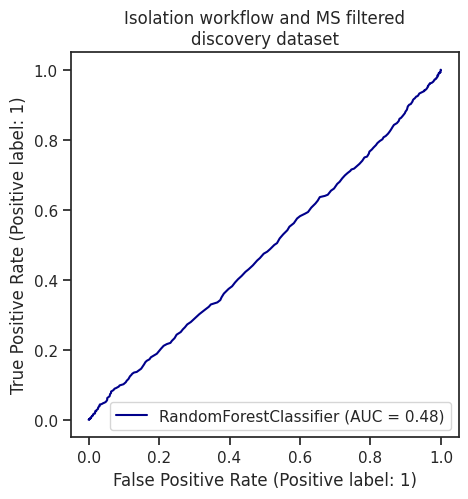

In [9]:
sns.set(style=("ticks"), font_scale=1)
fig, ax = plt.subplots(1, 1, figsize=(5,5))

RocCurveDisplay.from_estimator(rf_3, test_X_3, test_y_3, color="darkblue", ax=ax)
ax.set(title="Isolation workflow and MS filtered\ndiscovery dataset")

plt.show()

### Check feature importance

In [10]:
feature_dict = {'Palmitoylation_all':'Palmitoylation¹', 
                'PTM_Uniprot':'PTM¹', 
                'molecular_weight':'Molecular weight',
                'Instability_index':'Instability index',
                'length':'Sequence length', 
                'turn':'Turn', 
                'Acetylation_all':'Acetylation¹',
                'tasa_netsurfp2':'TASA', 
                'thsa_netsurfp2':'THSA',
                'disorder':'Disorder', 
                'D_exposed':'Exposed D', 
                'Ubiquitination_all':'Ubiquitination¹', 
                'sheet':'Sheet', 
                'Sum_AA_exposed': 'Exposed residues', 
                'S_exposed':'Exposed S', 
                'Aggregation_propensity':'Aggregation propensity',
                'L_exposed':'Exposed L', 
                'rhsa_netsurfp2':'RHSA', 
                'Isoelectric_point':'Isoelectric point', 
                'Charge_at_7':'Charge at pH 7',
                'on_surface': 'Hydrophobic residues on surface', 
                'Methylation_all':'Methylation¹', 
                'Charge_at_5':'Charge at pH 5', 
                'helix':'Helix',
                'hydr_count':'Hydrophobic residues', 
                'G_exposed':'Exposed G', 
                'H_exposed':'Exposed H',
                'Q_exposed':'Exposed Q', 
                'N_exposed':'Exposed N', 
                'C_exposed':'Exposed C', 
                'A_exposed':'Exposed A', 
                'K_exposed':'Exposed K', 
                'V_exposed':'Exposed V', 
                'E_exposed':'Exposed E', 
                'M_exposed':'Exposed M', 
                'T_exposed':'Exposed T', 
                'Glycosylation_all':'Glycosylation¹', 
                'R_exposed':'Exposed R', 
                'P_exposed':'Exposed P', 
                'Y_exposed':'Exposed Y',
                'polar_count':'Polar residues', 
                'F_exposed':'Exposed F', 
                'I_exposed':'Exposed I', 
                'Nitrosylation_all':'Nitrosylation¹',
                'W_exposed':'Exposed W', 
                'Acetylation_MSD':'Acetylation predicted', 
                'Phosphorylation_all':'Phosphorylation¹', 
                'transmembrane':'Transmembrane',
                'SUMOylation_MSD':'SUMOylation predicted', 
                'Methylation_MSD':'Methylation predicted', 
                'Palmitoylation_MSD':'Palmitoylation predicted', 
                'coiled_coil': 'Coiled coil domain', 
                'Lipoprotein_UP':'Lipoprotein¹', 
                'Glycosylation_MSD':'Glycosylation predicted',
                'SUMOylation_all':'SUMOylation¹',
                'Phosphorylation_MSD':'Phosphorylation predicted',
                'Ubiquitination_MSD':'Ubiquitination predicted',
                'PTM_MSD':'PTM predicted',
                'Myristoylation_all':'Myristoylation¹', 
                'Prenylation_Uniprot':'Prenylation¹', 
                'GPI-anchor_Uniprot':'GPI-anchor¹', 
                'ww_domain':'WW domain',
                'NEDDylation_Uniprot':'NEDDylation¹', 
                'RAS_profile':'RAS profile', 
                'Citrullination_Uniprot':'Citrullination¹', 
                'Nitration_Uniprot':'Nitration¹',
                'ISGylation_Uniprot':'ISGylation¹',
                'HSP':'HSP¹',
                'Polar_exposed':'Exposed polar residues',
                'Hydrophobic_exposed':'Exposed hydrophobic residues'}

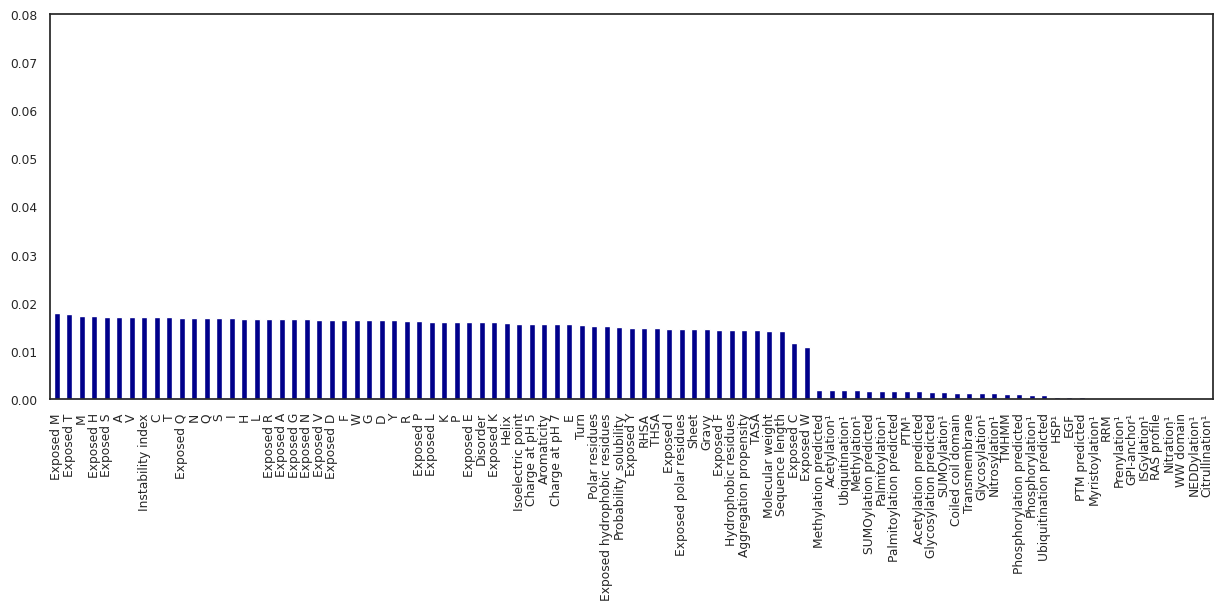

In [11]:
sns.set(font_scale=0.8, style="white")
fig, ax = plt.subplots(1, 1, figsize=(15,5))

col_names = [feature_dict[x] if x in feature_dict.keys() else x for x in train_X_3.columns]

feature_importance_rf3 = pd.DataFrame(data={"Importance_RF3_random":rf_3.feature_importances_}, index=col_names)
feature_importance_rf3["Importance_RF3_random"].sort_values(ascending=False).plot(kind='bar', color='darkblue')
ax.set_ylim((0,0.08))

plt.show()

## Save feature importance of random model

In [12]:
feature_importance_rf3.to_csv('FI_Random_model.csv')